In [1]:
from read_training_data import get_tension_data, get_raw_data, get_lengths, calculate_res_freq
import pandas as pd
import numpy as np

In [ ]:
# training data
raw_data_path = "/vols/dune/sb3423/DWA/training-data/raw/APA_5947a8b0-5152-11ed-84c6-9170f34dd096b_apa4_training"
processed_data_path = "/vols/dune/sb3423/DWA/training-data/processed/5947a8b0-5152-11ed-84c6-9170f34dd096b_apa4_training.json"

proc_scans = get_tension_data(processed_data_path, ["U", "X"])

keys_to_remove = {"scanEndMode", "measuredBy", "stage", "apaUuid", "type"}
raw_scans = get_raw_data(raw_data_path, keys_to_remove)

proc_df = pd.DataFrame(proc_scans)
raw_df = pd.DataFrame(raw_scans)

comb_df = pd.merge(raw_df, proc_df, on="uid", how="outer")

final_comb_df = comb_df.dropna(subset=['tension'])
numeric_tension = pd.to_numeric(final_comb_df['tension'], errors='coerce') # removes tensions that aren't found
final_comb_df['tension'] = numeric_tension

u_side_lengths = get_lengths("/vols/dune/sb3423/DWA/training-data/tensions/U_Layer_Tension_Template.xlsx", "U")
x_side_lengths = get_lengths("/vols/dune/sb3423/DWA/training-data/tensions/X_Layer_Tension_Template.xlsx", "X")

final_df = pd.merge(final_comb_df, u_side_lengths, on="uid", how="inner") # this only includes U layer wires

x_wires = final_comb_df[final_comb_df["uid"].str.startswith("X", na=False)]
x_wires["length"] = x_side_lengths

final_df = pd.concat([final_df, x_wires], ignore_index=True) # reincludes X layers

tension = final_df['tension'].values
lengths = final_df['length'].values / 1000 # in meters
rho = 1.52e-4

res_freq = calculate_res_freq(tension, lengths, rho) # in Hz
final_df['res_freq'] = res_freq

In [1]:
from read_training_data import get_tension_data, get_raw_data, get_lengths, calculate_res_freq, create_torch_datasets
import pandas as pd
import numpy as np

# testing new dataset
new_raw_path = "/vols/dune/amh24/APA-DWA-measurements/4ml/scanData/raw/APA_APA30_PostCold_27_01_26/"
new_proc_path = "/vols/dune/amh24/APA-DWA-measurements/4ml/scanData/processed/APA30_PostCold_27_01_26.json"

proc_scans = get_tension_data(new_proc_path, stage="DWA Development")
keys_to_remove = {"scanEndMode", "measuredBy", "apaUuid", "type"}
raw_scans = get_raw_data(new_raw_path, keys_to_remove)

proc_df = pd.DataFrame(proc_scans)
raw_df = pd.DataFrame(raw_scans)

# comb_df = pd.merge(raw_df, proc_df, on=["uid", "parent_folder"], how="outer")
comb_df = pd.merge(raw_df, proc_df, on=["uid", "parent_folder"], how="outer")
final_comb_df = comb_df.dropna(subset=['tension'])

u_side_lengths = get_lengths("/vols/dune/sb3423/DWA/training-data/tensions/U_Layer_Tension_Template.xlsx", "U")
v_side_lengths = get_lengths("/vols/dune/sb3423/DWA/training-data/tensions/V_Layer_Tension_Template.xlsx", "V")
x_side_lengths = get_lengths("/vols/dune/sb3423/DWA/training-data/tensions/X_Layer_Tension_Template.xlsx", "X")
g_side_lengths = get_lengths("/vols/dune/sb3423/DWA/training-data/tensions/G_Layer_Tension_Template.xlsx", "G")

full_u_df = pd.merge(final_comb_df, u_side_lengths, on="uid", how="inner") # this only includes U layer wires
full_v_df = pd.merge(final_comb_df, v_side_lengths, on="uid", how="inner")

full_x_df = final_comb_df[final_comb_df["uid"].str.startswith("X", na=False)]
full_x_df["length"] = x_side_lengths

full_g_df = final_comb_df[final_comb_df["uid"].str.startswith("G", na=False)]
full_g_df["length"] = g_side_lengths

df_list = [full_u_df, full_v_df, full_x_df, full_g_df]
final_df = pd.concat(df_list, ignore_index=True)

tension = final_df['tension'].values
lengths = final_df['length'].values / 1000 # in meters

rho = 1.52e-4
 
res_freq = calculate_res_freq(tension, lengths, rho) # in Hz
final_df['res_freq'] = res_freq

final_df = final_df.drop(columns=["segment_id", "channel_index", "layer", "stage", "headboardNumber", "side"])
# final_df.head(3)

In [2]:
freq = final_df['freq'].values
rounded_res_freq = np.round(res_freq * 8, 0) / 8
step = 0.125
res_freq_map = []

for i in range(len(freq)):
    start_freq = freq[i][0]
    curr_res_freq_map = np.zeros((len(freq[i]),), dtype=int)
    index = int(round((rounded_res_freq[i] - start_freq) / step))
    curr_res_freq_map.put([index - 2, index - 1, index, index + 1, index + 2], [1, 1, 1, 1, 1])
    res_freq_map.append(curr_res_freq_map)

final_df['res_freq_map'] = res_freq_map

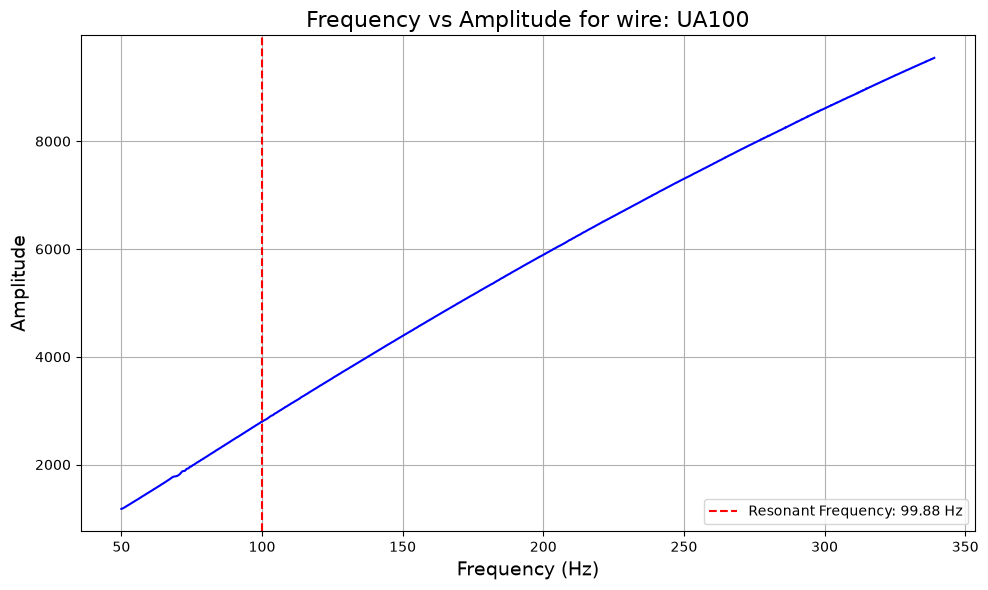

In [6]:
from visualisation import plot_scans

freq = final_df['freq'].values[0]
ampl = final_df['ampl'].values[0]
wire = final_df['uid'].values[0]
res_freq = final_df['res_freq'].values[0]
plot_scans(freq, ampl, wire, res_freq)

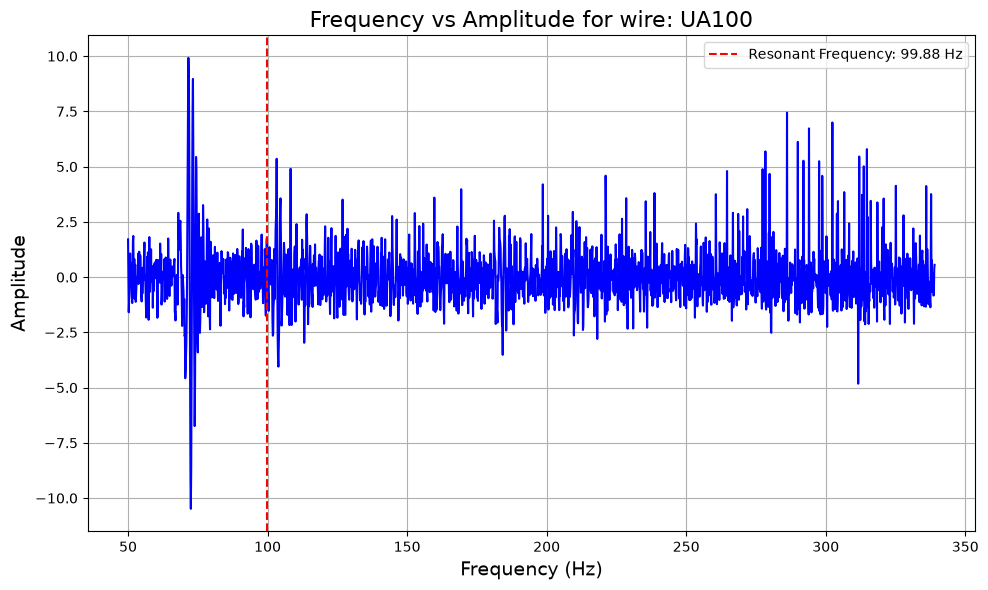

In [7]:
from read_training_data import baseline_subtracted

freq = final_df['freq'].values[0]
ampl = baseline_subtracted(freq, final_df['ampl'].values[0])
wire = final_df['uid'].values[0]
res_freq = final_df['res_freq'].values[0]
plot_scans(freq, ampl, wire, res_freq)

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

X_padded, y_tensor = create_torch_datasets(final_df, sig2sig=True)

In [4]:
from torch.utils.data import TensorDataset, random_split

dataset = TensorDataset(X_padded[0:100], y_tensor[0:100]) # testing on small subset
dataset_train, dataset_test = random_split(dataset, lengths = [0.8, 0.2], generator=torch.Generator().manual_seed(42))  # 80% train, 20% test

dloader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)
dloader_test = DataLoader(dataset_test, batch_size=32, shuffle=True)

In [5]:
from models import sig2sig_unet
import tensorflow as tf
from training_testing import train_keras_model

model = sig2sig_unet(X_padded.shape[1], X_padded.shape[2])
model_path = "UNet/model01.keras"
epochs = 30
batch_size = 32
patience = 6
optimizer='adam'
loss=tf.keras.losses.BinaryCrossentropy()

losses, train_time = train_keras_model(model, dloader_train, epochs, model_path, optimizer, loss, batch_size, patience)

I0000 00:00:1794234971.987895 3020734 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794234972.049446 3020734 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794234974.767905 3020734 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794234974.770049 3020734 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

Starting training...
Epoch 1/30


I0000 00:00:1794234976.604481 3020734 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 2.3403 - mean_io_u: 0.4354
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.1753 - mean_io_u: 0.4981
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 0.1385 - mean_io_u: 0.4982
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - loss: 0.1174 - mean_io_u: 0.4982
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - loss: 0.1049 - mean_io_u: 0.4982
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 0.0923 - mean_io_u: 0.4982
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 0.0811 - mean_io_u: 0.4983
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 0.0743 - mean_io_u: 0.4983
Epoch 9/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - loss: 0.0695 - mean_io_u: 0.4983
Epoch 10/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 0.0670 - mean_io_u: 0.4983
Epoch 11/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - loss: 0.0642 - mean_io_u: 0.4983
Epoch 12/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 0.0624 - mean_io_u: 0.4983

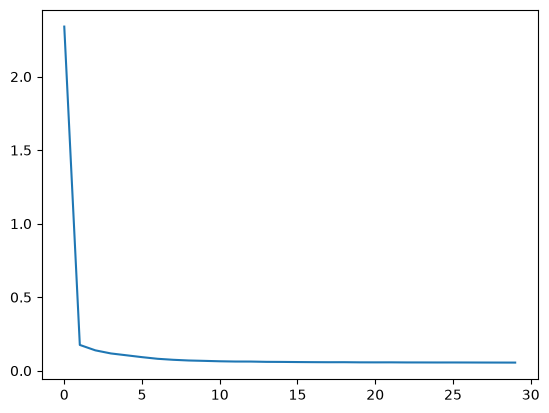

In [8]:
from matplotlib import pyplot as plt
fig, ax = plt.subplots()
ax.plot(losses['loss'], label='Training Loss')

In [10]:
losses.keys()

dict_keys(['loss', 'mean_io_u'])